In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/superstore_clean.csv",
    parse_dates=["order_date", "ship_date", "month_start"]
)

df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,discount,profit,revenue,cogs,profit_margin,year,month,month_name,quarter,month_start
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0.00,41.9136,261.9600,220.0464,16.00,2016,11,November,4,2016-11-01
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0.00,219.5820,731.9400,512.3580,30.00,2016,11,November,4,2016-11-01
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,0.00,6.8714,14.6200,7.7486,47.00,2016,6,June,2,2016-06-01
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0.45,-383.0310,957.5775,1340.6085,-40.00,2015,10,October,4,2015-10-01
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0.20,2.5164,22.3680,19.8516,11.25,2015,10,October,4,2015-10-01


In [42]:
monthly_revenue = (
    df.groupby("month_start", as_index=False)
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique")
      )
      .sort_values("month_start")
)

monthly_revenue.head()

,month_start,revenue,profit,orders,customers
0,2014-01-01,14236.895,2450.1907,32,32
1,2014-02-01,4519.892,862.3084,28,27
2,2014-03-01,55691.009,498.7299,71,69
3,2014-04-01,28295.345,3488.8352,66,64
4,2014-05-01,23648.287,2738.7096,69,67


In [43]:
monthly_revenue.tail()

,month_start,revenue,profit,orders,customers
43,2017-08-01,63120.8880,9040.9557,111,104
44,2017-09-01,87866.6520,10991.5556,226,196
45,2017-10-01,77776.9232,9275.2755,147,136
46,2017-11-01,118447.8250,9690.1037,261,216
47,2017-12-01,83829.3188,8483.3468,224,195


In [44]:
print("Start date:", monthly_revenue["month_start"].min())
print("End date:", monthly_revenue["month_start"].max())
print("Number of months:", len(monthly_revenue))

Start date: 2014-01-01 00:00:00
End date: 2017-12-01 00:00:00
Number of months: 48


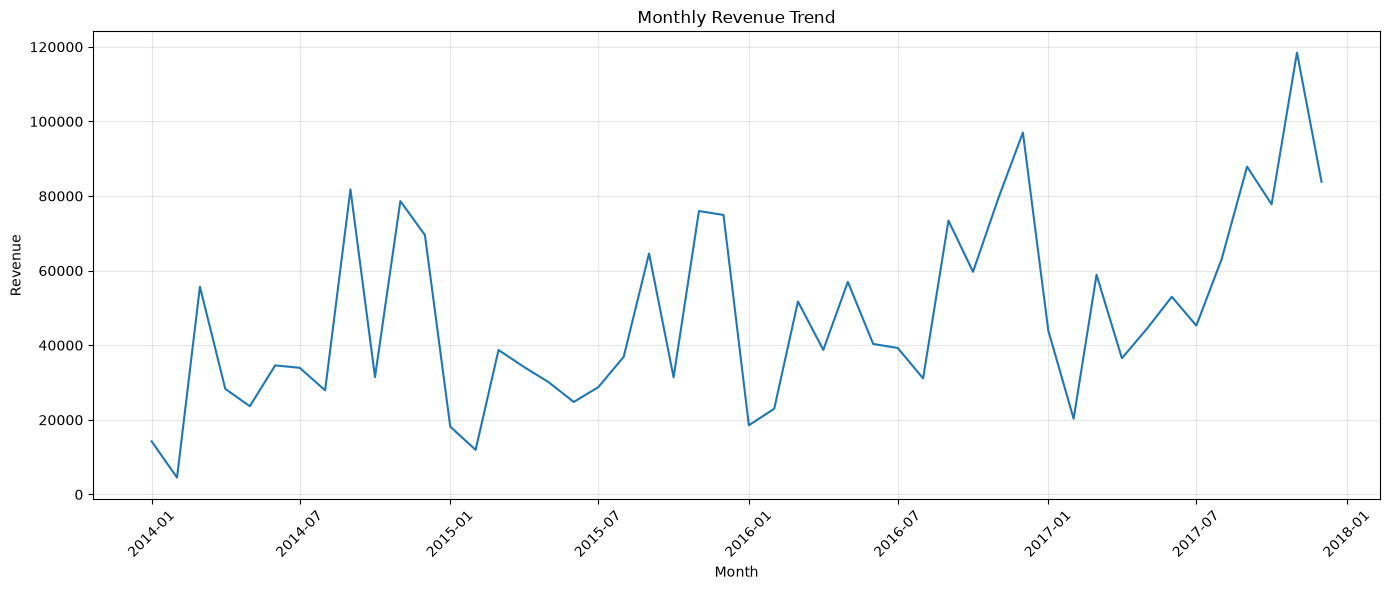

In [45]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["month_start"],
    monthly_revenue["revenue"]
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
monthly_revenue["revenue_ma_3"] = (
    monthly_revenue["revenue"]
    .rolling(window=3)
    .mean()
)

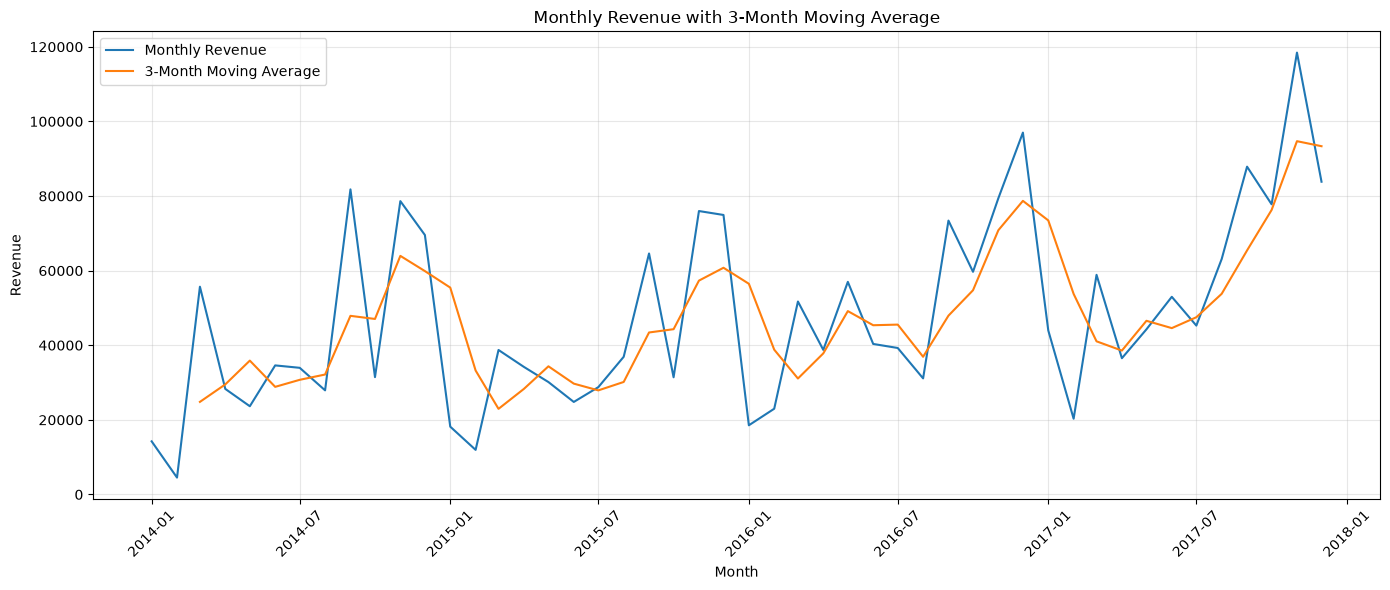

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["month_start"],
    monthly_revenue["revenue"],
    label="Monthly Revenue"
)

plt.plot(
    monthly_revenue["month_start"],
    monthly_revenue["revenue_ma_3"],
    label="3-Month Moving Average"
)

plt.title("Monthly Revenue with 3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
monthly_revenue["year"] = (
    monthly_revenue["month_start"].dt.year
)

monthly_revenue["month"] = (
    monthly_revenue["month_start"].dt.month
)

In [49]:
monthly_pivot = monthly_revenue.pivot(
    index="month",
    columns="year",
    values="revenue"
)

monthly_pivot

year,2014,2015,2016,2017
month,,,,
1,14236.8950,18174.0756,18542.4910,43971.3740
2,4519.8920,11951.4110,22978.8150,20301.1334
3,55691.0090,38726.2520,51715.8750,58872.3528
4,28295.3450,34195.2085,38750.0390,36521.5361
5,23648.2870,30131.6865,56987.7280,44261.1102
6,34595.1276,24797.2920,40344.5340,52981.7257
7,33946.3930,28765.3250,39261.9630,45264.4160
8,27909.4685,36898.3322,31115.3743,63120.8880
9,81777.3508,64595.9180,73410.0249,87866.6520


In [50]:
seasonality = (
    monthly_revenue
    .groupby("month")["revenue"]
    .agg(["mean", "min", "max"])
    .reset_index()
)

seasonality

,month,mean,min,max
0,1,23731.208900,14236.8950,43971.3740
1,2,14937.812850,4519.8920,22978.8150
2,3,51251.372200,38726.2520,58872.3528
3,4,34440.532150,28295.3450,38750.0390
4,5,38757.202925,23648.2870,56987.7280
5,6,38179.669825,24797.2920,52981.7257
6,7,36809.524250,28765.3250,45264.4160
7,8,39761.015750,27909.4685,63120.8880
8,9,76912.486425,64595.9180,87866.6520
9,10,50080.746175,31404.9235,77776.9232


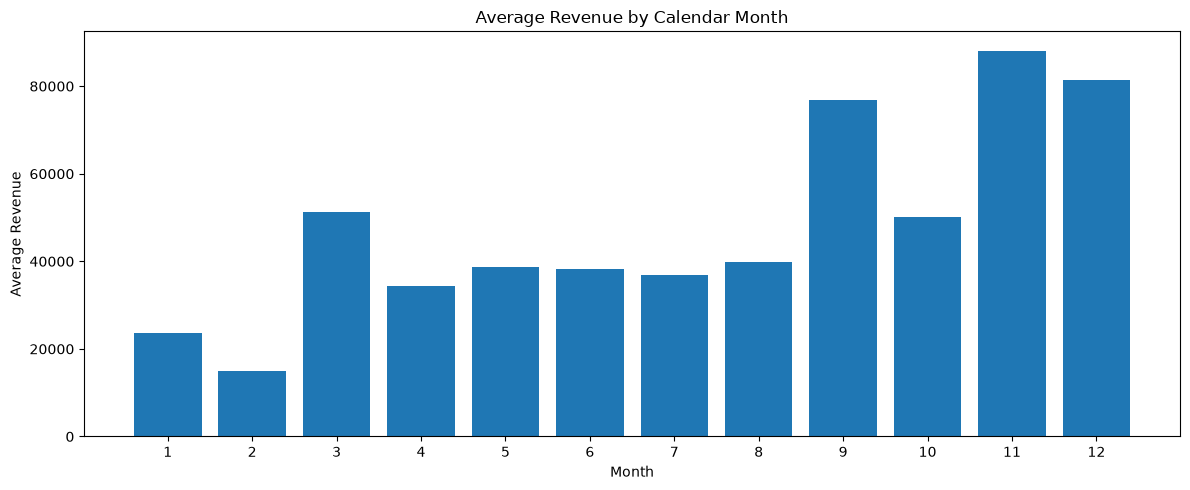

In [51]:
plt.figure(figsize=(12, 5))

plt.bar(
    seasonality["month"],
    seasonality["mean"]
)

plt.title("Average Revenue by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Revenue")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

Step 4B Monthly Profit Trend

In [52]:
monthly_profit = (
    df.groupby("month_start")
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum")
      )
      .reset_index()
)

monthly_profit["profit_margin"] = (
    monthly_profit["profit"] / monthly_profit["revenue"] * 100
)

monthly_profit["profit_3m_avg"] = (
    monthly_profit["profit"]
    .rolling(3)
    .mean()
)

monthly_profit.head()

,month_start,revenue,profit,profit_margin,profit_3m_avg
0,2014-01-01,14236.895,2450.1907,17.210148,NaN
1,2014-02-01,4519.892,862.3084,19.078075,NaN
2,2014-03-01,55691.009,498.7299,0.895530,1270.409667
3,2014-04-01,28295.345,3488.8352,12.330068,1616.624500
4,2014-05-01,23648.287,2738.7096,11.581006,2242.091567


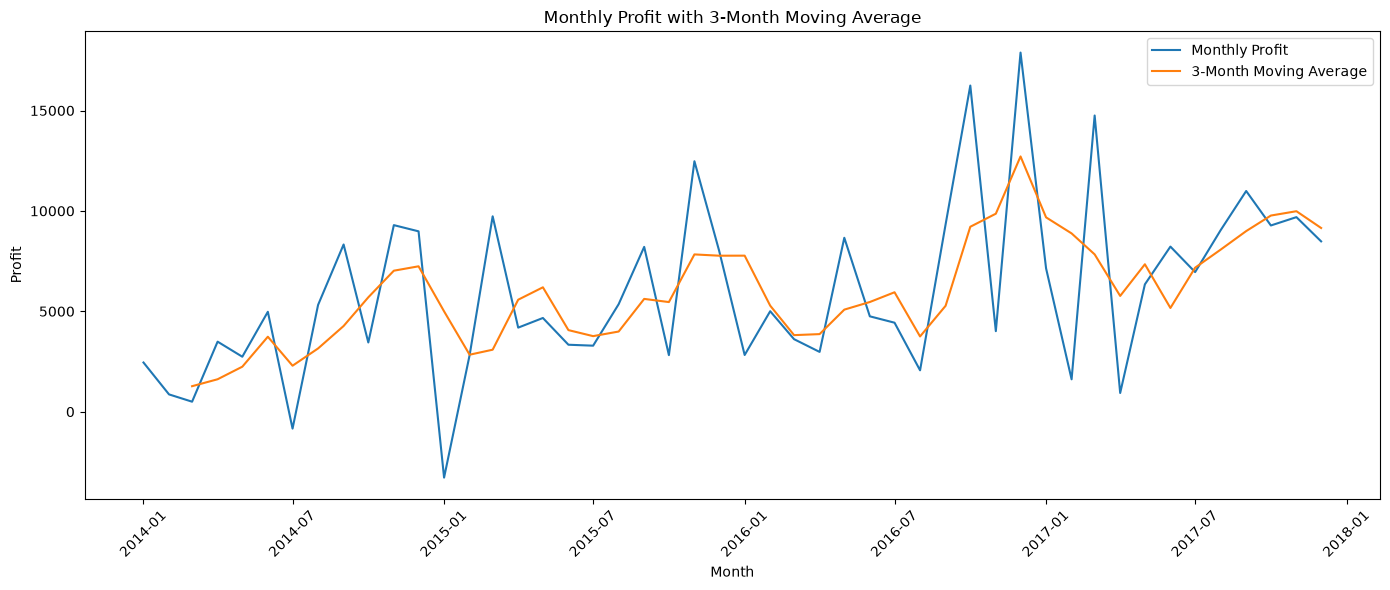

In [53]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_profit["month_start"],
    monthly_profit["profit"],
    label="Monthly Profit"
)

plt.plot(
    monthly_profit["month_start"],
    monthly_profit["profit_3m_avg"],
    label="3-Month Moving Average"
)

plt.title("Monthly Profit with 3-Month Moving Average")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Step 4C — Revenue & Profit Year-over-Year Growth

In [54]:
annual_trend = (
    df.groupby("year")
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique"),
          units=("quantity", "sum")
      )
      .reset_index()
)

annual_trend["profit_margin"] = (
    annual_trend["profit"] /
    annual_trend["revenue"] * 100
)

annual_trend["revenue_growth"] = (
    annual_trend["revenue"].pct_change() * 100
)

annual_trend["profit_growth"] = (
    annual_trend["profit"].pct_change() * 100
)

annual_trend

,year,revenue,profit,orders,customers,units,profit_margin,revenue_growth,profit_growth
0,2014,484247.4981,49543.9741,969,595,7581,10.231126,NaN,NaN
1,2015,470532.5090,61618.6037,1038,573,7979,13.095504,-2.832227,24.371540
2,2016,609205.5980,81795.1743,1315,638,9837,13.426530,29.471521,32.744284
3,2017,733215.2552,93439.2696,1687,693,12476,12.743771,20.355962,14.235675


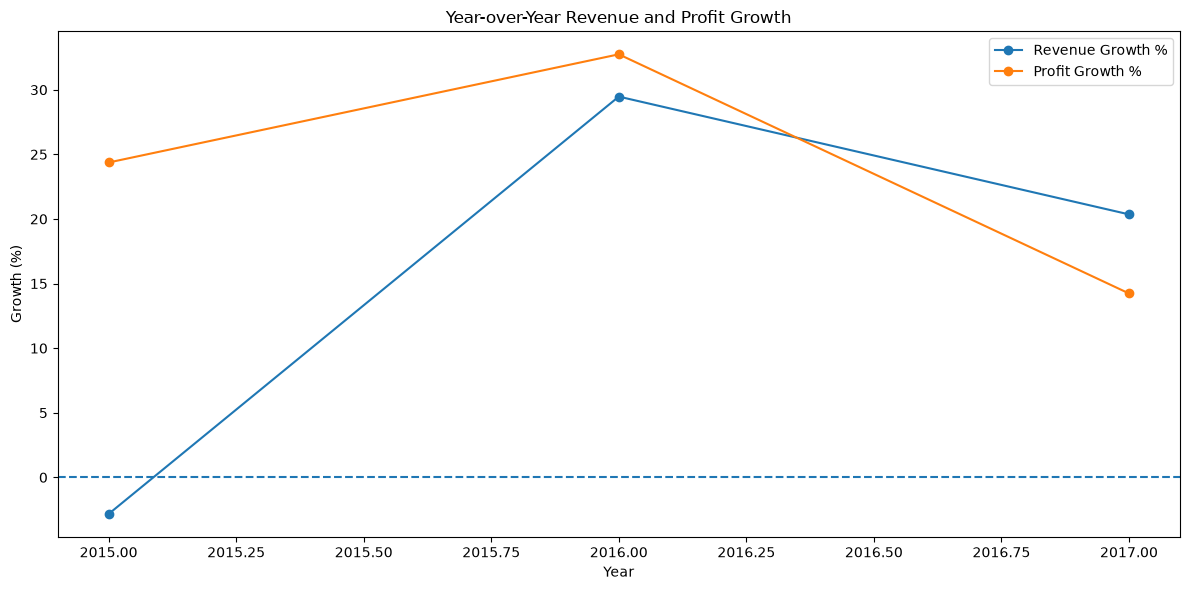

In [55]:
plt.figure(figsize=(12, 6))

plt.plot(
    annual_trend["year"],
    annual_trend["revenue_growth"],
    marker="o",
    label="Revenue Growth %"
)

plt.plot(
    annual_trend["year"],
    annual_trend["profit_growth"],
    marker="o",
    label="Profit Growth %"
)

plt.axhline(0, linestyle="--")

plt.title("Year-over-Year Revenue and Profit Growth")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.legend()

plt.tight_layout()
plt.show()

Step 4D — Seasonality Analysis

In [56]:
monthly_seasonality = (
    df.groupby("month")
      .agg(
          revenue=("revenue", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          units=("quantity", "sum")
      )
      .reset_index()
)

monthly_seasonality["profit_margin"] = (
    monthly_seasonality["profit"] /
    monthly_seasonality["revenue"] * 100
)

monthly_seasonality

,month,revenue,profit,orders,units,profit_margin
0,1,94924.8356,9134.4461,178,1475,9.622820
1,2,59751.2514,10294.6107,162,1067,17.229113
2,3,205005.4888,28594.6872,354,2564,13.948254
3,4,137762.1286,11587.4363,343,2447,8.411191
4,5,155028.8117,22411.3078,369,2791,14.456221
5,6,152718.6793,21285.7954,364,2680,13.937912
6,7,147238.0970,13832.6648,338,2705,9.394759
7,8,159044.0630,21776.9384,341,2784,13.692393
8,9,307649.9457,36857.4753,688,5062,11.980329
9,10,200322.9847,31784.0413,417,3104,15.866398


In [57]:
monthly_seasonality.sort_values(
    "revenue",
    ascending=False
)

,month,revenue,profit,orders,units,profit_margin
10,11,352461.0710,35468.4265,753,5775,10.063076
11,12,325293.5035,43369.1919,702,5419,13.332326
8,9,307649.9457,36857.4753,688,5062,11.980329
2,3,205005.4888,28594.6872,354,2564,13.948254
9,10,200322.9847,31784.0413,417,3104,15.866398
7,8,159044.0630,21776.9384,341,2784,13.692393
4,5,155028.8117,22411.3078,369,2791,14.456221
5,6,152718.6793,21285.7954,364,2680,13.937912
6,7,147238.0970,13832.6648,338,2705,9.394759
3,4,137762.1286,11587.4363,343,2447,8.411191


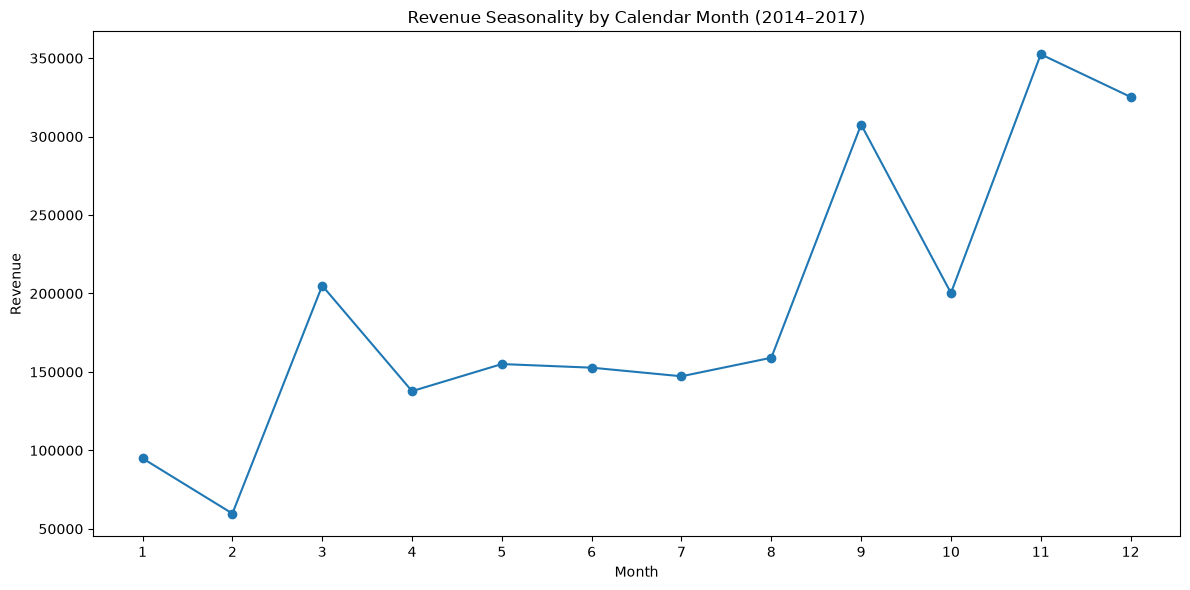

In [58]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_seasonality["month"],
    monthly_seasonality["revenue"],
    marker="o"
)

plt.title("Revenue Seasonality by Calendar Month (2014–2017)")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

Step 4E — Seasonality Index

In [59]:
seasonality = monthly_seasonality.copy()

average_monthly_revenue = seasonality["revenue"].mean()

seasonality["revenue_index"] = (
    seasonality["revenue"] /
    average_monthly_revenue
) * 100

seasonality = seasonality.sort_values(
    "revenue_index",
    ascending=False
)

seasonality[
    [
        "month",
        "revenue",
        "revenue_index",
        "profit",
        "profit_margin"
    ]
]

,month,revenue,revenue_index,profit,profit_margin
10,11,352461.0710,184.116806,35468.4265,10.063076
11,12,325293.5035,169.925151,43369.1919,13.332326
8,9,307649.9457,160.708600,36857.4753,11.980329
2,3,205005.4888,107.089715,28594.6872,13.948254
9,10,200322.9847,104.643693,31784.0413,15.866398
7,8,159044.0630,83.080622,21776.9384,13.692393
4,5,155028.8117,80.983155,22411.3078,14.456221
5,6,152718.6793,79.776400,21285.7954,13.937912
6,7,147238.0970,76.913482,13832.6648,9.394759
3,4,137762.1286,71.963474,11587.4363,8.411191


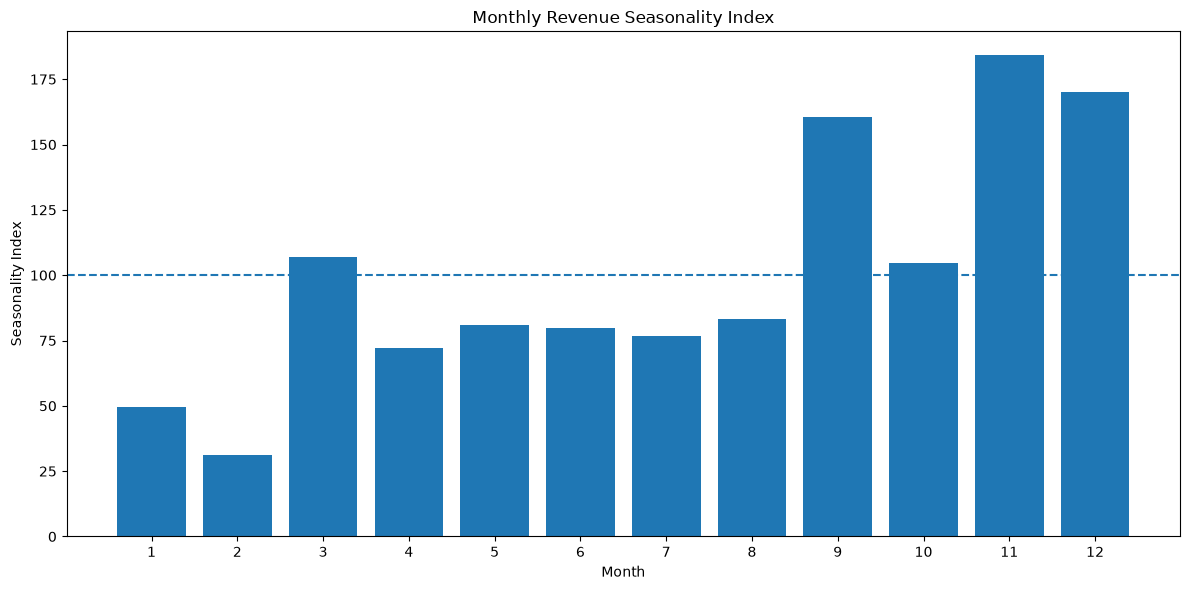

In [60]:
plt.figure(figsize=(12, 6))

plt.bar(
    seasonality["month"],
    seasonality["revenue_index"]
)

plt.axhline(100, linestyle="--")

plt.title("Monthly Revenue Seasonality Index")
plt.xlabel("Month")
plt.ylabel("Seasonality Index")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [61]:
# Seasonal performance classification

seasonality_analysis = monthly_revenue.copy()

seasonality_analysis["season"] = seasonality_analysis["month"].map({
    1: "Weak Season",
    2: "Weak Season",
    3: "Normal Season",
    4: "Normal Season",
    5: "Normal Season",
    6: "Normal Season",
    7: "Normal Season",
    8: "Normal Season",
    9: "Peak Season",
    10: "Peak Season",
    11: "Peak Season",
    12: "Peak Season"
})

season_summary = (
    seasonality_analysis
    .groupby("season")
    .agg(
        avg_revenue=("revenue", "mean"),
        avg_profit=("profit", "mean"),
        total_revenue=("revenue", "sum"),
        total_profit=("profit", "sum"),
        months=("month", "count")
    )
    .reset_index()
)

season_summary

,season,avg_revenue,avg_profit,total_revenue,total_profit,months
0,Normal Season,39866.552850,4978.701246,9.567973e+05,119488.8299,24
1,Peak Season,74107.969056,9217.445938,1.185728e+06,147479.1350,16
2,Weak Season,19334.510875,2428.632100,1.546761e+05,19429.0568,8


In [62]:
peak_revenue = season_summary.loc[
    season_summary["season"] == "Peak Season",
    "avg_revenue"
].iloc[0]

weak_revenue = season_summary.loc[
    season_summary["season"] == "Weak Season",
    "avg_revenue"
].iloc[0]

peak_vs_weak = ((peak_revenue - weak_revenue) / weak_revenue) * 100

print(f"Peak season average revenue: ₹{peak_revenue:,.2f}")
print(f"Weak season average revenue: ₹{weak_revenue:,.2f}")
print(f"Peak vs weak revenue difference: {peak_vs_weak:.2f}%")

Peak season average revenue: ₹74,107.97
Weak season average revenue: ₹19,334.51
Peak vs weak revenue difference: 283.29%


Step 4F — Identify the best and worst months

In [63]:
best_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmax()
]

worst_month = monthly_revenue.loc[
    monthly_revenue["revenue"].idxmin()
]

print("Best revenue month:")
print(best_month)

print("\nWorst revenue month:")
print(worst_month)

Best revenue month:
month_start     2017-11-01 00:00:00
revenue                  118447.825
profit                    9690.1037
orders                          261
customers                       216
revenue_ma_3             94697.1334
year                           2017
month                            11
Name: 46, dtype: object

Worst revenue month:
month_start     2014-02-01 00:00:00
revenue                    4519.892
profit                     862.3084
orders                           28
customers                        27
revenue_ma_3                    NaN
year                           2014
month                             2
Name: 1, dtype: object


Step 4G — Identify recurring seasonal pattern

In [64]:
monthly_pattern = (
    monthly_revenue
    .assign(calendar_month=monthly_revenue["month_start"].dt.month)
    .groupby("calendar_month")
    .agg(
        avg_revenue=("revenue", "mean"),
        avg_profit=("profit", "mean")
    )
    .reset_index()
)

monthly_pattern["revenue_index"] = (
    monthly_pattern["avg_revenue"] /
    monthly_pattern["avg_revenue"].mean()
) * 100

monthly_pattern["profit_index"] = (
    monthly_pattern["avg_profit"] /
    monthly_pattern["avg_profit"].mean()
) * 100

monthly_pattern

,calendar_month,avg_revenue,avg_profit,revenue_index,profit_index
0,1,23731.208900,2283.611525,49.586349,38.273217
1,2,14937.812850,2573.652675,31.212552,43.134292
2,3,51251.372200,7148.671800,107.089715,119.811388
3,4,34440.532150,2896.859075,71.963474,48.551216
4,5,38757.202925,5602.826950,80.983155,93.903104
5,6,38179.669825,5321.448850,79.776400,89.187221
6,7,36809.524250,3458.166200,76.913482,57.958695
7,8,39761.015750,5444.234600,83.080622,91.245104
8,9,76912.486425,9214.368825,160.708600,154.432368
9,10,50080.746175,7946.010325,104.643693,133.174742


Step 4H — Quarterly Business Analysis

In [65]:
# Create quarterly performance analysis
# Built from the transaction-level df (not monthly_revenue), so that
# units are available and orders/customers are counted once per quarter

quarterly_summary = (
    df.assign(quarter_name="Q" + df["order_date"].dt.quarter.astype(str))
    .groupby("quarter_name")
    .agg(
        revenue=("revenue", "sum"),
        profit=("profit", "sum"),
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
        units=("quantity", "sum")
    )
    .reset_index()
)

quarterly_summary["profit_margin"] = (
    quarterly_summary["profit"] /
    quarterly_summary["revenue"] * 100
)

quarterly_summary["revenue_share"] = (
    quarterly_summary["revenue"] /
    quarterly_summary["revenue"].sum() * 100
)

quarterly_summary["profit_share"] = (
    quarterly_summary["profit"] /
    quarterly_summary["profit"].sum() * 100
)

quarterly_summary = quarterly_summary.sort_values(
    "revenue",
    ascending=False
)

quarterly_summary

,quarter_name,revenue,profit,orders,customers,units,profit_margin,revenue_share,profit_share
3,Q4,878077.5592,110621.6597,1872,709,14298,12.598165,38.223804,38.625283
2,Q3,613932.1057,72467.0785,1367,644,10551,11.803761,26.725225,25.303014
1,Q2,445509.6196,55284.5395,1076,583,7918,12.409281,19.393586,19.303462
0,Q1,359681.5758,48023.7440,694,468,5106,13.351739,15.657385,16.768241


In [66]:
# Identify strongest and weakest quarters

best_quarter = quarterly_summary.loc[
    quarterly_summary["revenue"].idxmax()
]

worst_quarter = quarterly_summary.loc[
    quarterly_summary["revenue"].idxmin()
]

print("Best quarter:")
print(best_quarter)

print("\nWorst quarter:")
print(worst_quarter)

Best quarter:
quarter_name              Q4
revenue          878077.5592
profit           110621.6597
orders                  1872
customers                709
units                  14298
profit_margin      12.598165
revenue_share      38.223804
profit_share       38.625283
Name: 3, dtype: object

Worst quarter:
quarter_name              Q1
revenue          359681.5758
profit             48023.744
orders                   694
customers                468
units                   5106
profit_margin      13.351739
revenue_share      15.657385
profit_share       16.768241
Name: 0, dtype: object


In [67]:
# Compare Q4 against Q1

q4_revenue = quarterly_summary.loc[
    quarterly_summary["quarter_name"] == "Q4",
    "revenue"
].iloc[0]

q1_revenue = quarterly_summary.loc[
    quarterly_summary["quarter_name"] == "Q1",
    "revenue"
].iloc[0]

q4_vs_q1 = ((q4_revenue - q1_revenue) / q1_revenue) * 100

print(f"Q4 revenue: ₹{q4_revenue:,.2f}")
print(f"Q1 revenue: ₹{q1_revenue:,.2f}")
print(f"Q4 vs Q1 revenue difference: {q4_vs_q1:.2f}%")

Q4 revenue: ₹878,077.56
Q1 revenue: ₹359,681.58
Q4 vs Q1 revenue difference: 144.13%


Forecasting Work

In [68]:

# 1. Check the dataset structure
print("Dataset shape:", monthly_revenue.shape)
print("\nFirst 5 rows:")
display(monthly_revenue.head())

print("\nLast 5 rows:")
display(monthly_revenue.tail())

# 2. Check date range
print("\nStart month:", monthly_revenue["month_start"].min())
print("End month:", monthly_revenue["month_start"].max())

# 3. Check duplicate months
print(
    "Duplicate months:",
    monthly_revenue["month_start"].duplicated().sum()
)

# 4. Check missing values
print("\nMissing values:")
display(monthly_revenue.isnull().sum())

# 5. Check whether any months are missing
expected_months = pd.date_range(
    start=monthly_revenue["month_start"].min(),
    end=monthly_revenue["month_start"].max(),
    freq="MS"
)

actual_months = pd.DatetimeIndex(
    monthly_revenue["month_start"]
)

missing_months = expected_months.difference(actual_months)

print("\nExpected monthly observations:", len(expected_months))
print("Actual monthly observations:", len(actual_months))
print("Missing months:", list(missing_months))

# 6. Verify chronological order
print(
    "\nChronologically sorted:",
    monthly_revenue["month_start"].is_monotonic_increasing
)


Dataset shape: (48, 8)

First 5 rows:


,month_start,revenue,profit,orders,customers,revenue_ma_3,year,month
0,2014-01-01,14236.895,2450.1907,32,32,NaN,2014,1
1,2014-02-01,4519.892,862.3084,28,27,NaN,2014,2
2,2014-03-01,55691.009,498.7299,71,69,24815.932000,2014,3
3,2014-04-01,28295.345,3488.8352,66,64,29502.082000,2014,4
4,2014-05-01,23648.287,2738.7096,69,67,35878.213667,2014,5



Last 5 rows:


,month_start,revenue,profit,orders,customers,revenue_ma_3,year,month
43,2017-08-01,63120.8880,9040.9557,111,104,53789.009900,2017,8
44,2017-09-01,87866.6520,10991.5556,226,196,65417.318667,2017,9
45,2017-10-01,77776.9232,9275.2755,147,136,76254.821067,2017,10
46,2017-11-01,118447.8250,9690.1037,261,216,94697.133400,2017,11
47,2017-12-01,83829.3188,8483.3468,224,195,93351.355667,2017,12



Start month: 2014-01-01 00:00:00
End month: 2017-12-01 00:00:00
Duplicate months: 0

Missing values:


month_start     0
revenue         0
profit          0
orders          0
customers       0
revenue_ma_3    2
year            0
month           0
dtype: int64


Expected monthly observations: 48
Actual monthly observations: 48
Missing months: []

Chronologically sorted: True


In [69]:

# Check data quality
print("Duplicate months:", monthly_revenue["month_start"].duplicated().sum())
print("Missing values:\n", monthly_revenue[["month_start", "revenue", "profit"]].isnull().sum())
print("Chronologically sorted:", monthly_revenue["month_start"].is_monotonic_increasing)

# Use January 2014–December 2016 for training
train = monthly_revenue[
    monthly_revenue["month_start"] < "2017-01-01"
].copy()

# Use January–December 2017 for testing
test = monthly_revenue[
    monthly_revenue["month_start"] >= "2017-01-01"
].copy()

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))
print("Test period:", test["month_start"].min(), "to", test["month_start"].max())


Duplicate months: 0
Missing values:
 month_start    0
revenue        0
profit         0
dtype: int64
Chronologically sorted: True

Training observations: 36
Testing observations: 12
Test period: 2017-01-01 00:00:00 to 2017-12-01 00:00:00


In [70]:

# Create a copy of actual 2017 revenue
forecast = test[["month_start", "revenue"]].copy()

forecast = forecast.rename(
    columns={"revenue": "actual_revenue"}
)

# Predict each month using the same month from the previous year
previous_year_revenue = (
    train.set_index("month_start")["revenue"]
)

forecast["forecast_revenue"] = [
    previous_year_revenue.loc[
        date - pd.DateOffset(years=1)
    ]
    for date in forecast["month_start"]
]

# Calculate forecast error
forecast["error"] = (
    forecast["actual_revenue"] - forecast["forecast_revenue"]
)

display(forecast.round(2))


C:\Users\Aniket Mane\AppData\Local\Temp\ipykernel_29632\334908939.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast.round(2))


,month_start,actual_revenue,forecast_revenue,error
36,2017-01-01,43971.37,18542.49,25428.88
37,2017-02-01,20301.13,22978.82,-2677.68
38,2017-03-01,58872.35,51715.88,7156.48
39,2017-04-01,36521.54,38750.04,-2228.50
40,2017-05-01,44261.11,56987.73,-12726.62
41,2017-06-01,52981.73,40344.53,12637.19
42,2017-07-01,45264.42,39261.96,6002.45
43,2017-08-01,63120.89,31115.37,32005.51
44,2017-09-01,87866.65,73410.02,14456.63
45,2017-10-01,77776.92,59687.74,18089.18


In [71]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = forecast["actual_revenue"]
predicted = forecast["forecast_revenue"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = np.mean(np.abs((actual - predicted) / actual)) * 100

print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")


MAE:  $15,467.89
RMSE: $18,985.70
MAPE: 24.52%


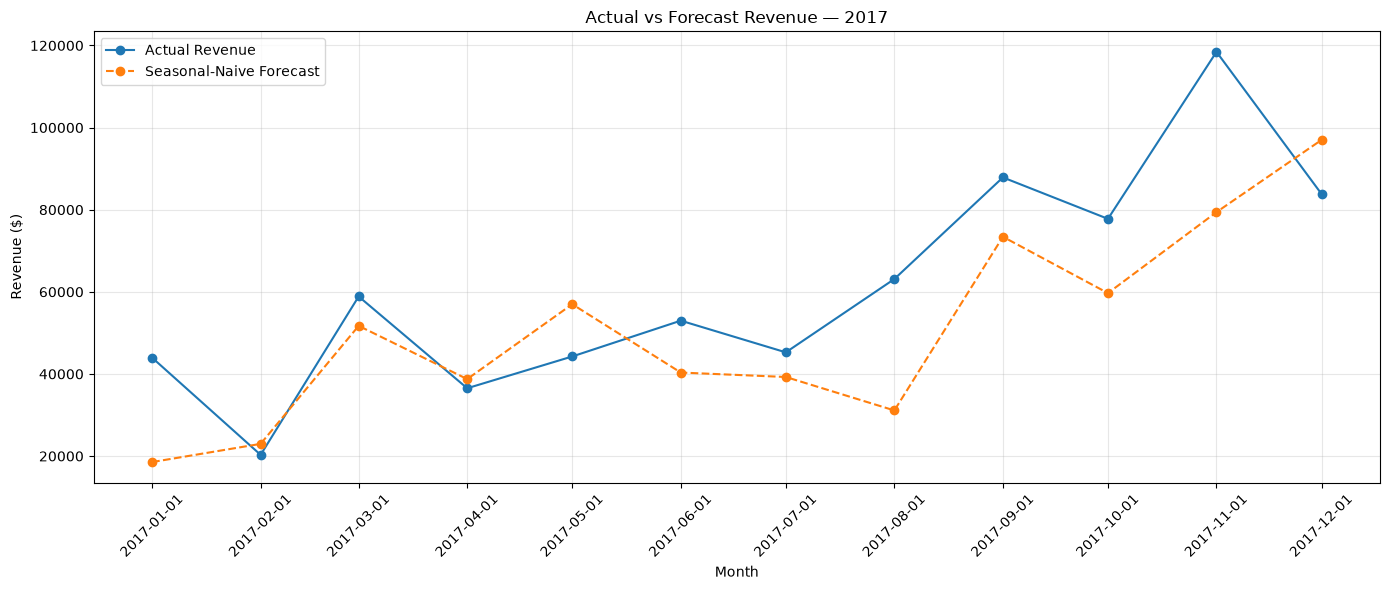

In [72]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    forecast["month_start"],
    forecast["actual_revenue"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    forecast["month_start"],
    forecast["forecast_revenue"],
    marker="o",
    linestyle="--",
    label="Seasonal-Naive Forecast"
)

plt.title("Actual vs Forecast Revenue — 2017")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(forecast["month_start"], rotation=45)
plt.tight_layout()
plt.show()


second model

In [74]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Prepare monthly revenue series for training
train_series = (
    train.set_index("month_start")["revenue"]
    .asfreq("MS")
)

# Fit a model with trend and 12-month seasonality
hw_model = ExponentialSmoothing(
    train_series,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hw_fit = hw_model.fit()

# Forecast the 12 months of 2017
hw_predictions = hw_fit.forecast(12)

# Compare with actual 2017 revenue
hw_results = test[["month_start", "revenue"]].copy()
hw_results = hw_results.rename(
    columns={"revenue": "actual_revenue"}
)
hw_results["hw_forecast"] = hw_predictions.to_numpy()

# Evaluate accuracy
actual = hw_results["actual_revenue"]
predicted = hw_results["hw_forecast"]

hw_mae = mean_absolute_error(actual, predicted)
hw_rmse = np.sqrt(mean_squared_error(actual, predicted))
hw_mape = np.mean(np.abs((actual - predicted) / actual)) * 100

print(f"Holt-Winters MAE:  ${hw_mae:,.2f}")
print(f"Holt-Winters RMSE: ${hw_rmse:,.2f}")
print(f"Holt-Winters MAPE: {hw_mape:.2f}%")

display(hw_results.round(2))


Holt-Winters MAE:  $11,452.92
Holt-Winters RMSE: $12,540.90
Holt-Winters MAPE: 22.59%


C:\Users\Aniket Mane\AppData\Local\Temp\ipykernel_29632\3402177190.py:44: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(hw_results.round(2))


,month_start,actual_revenue,hw_forecast
36,2017-01-01,43971.37,33011.50
37,2017-02-01,20301.13,31279.36
38,2017-03-01,58872.35,65133.84
39,2017-04-01,36521.54,53341.56
40,2017-05-01,44261.11,58754.26
41,2017-06-01,52981.73,53249.84
42,2017-07-01,45264.42,55948.37
43,2017-08-01,63120.89,55899.39
44,2017-09-01,87866.65,97893.36
45,2017-10-01,77776.92,63035.86


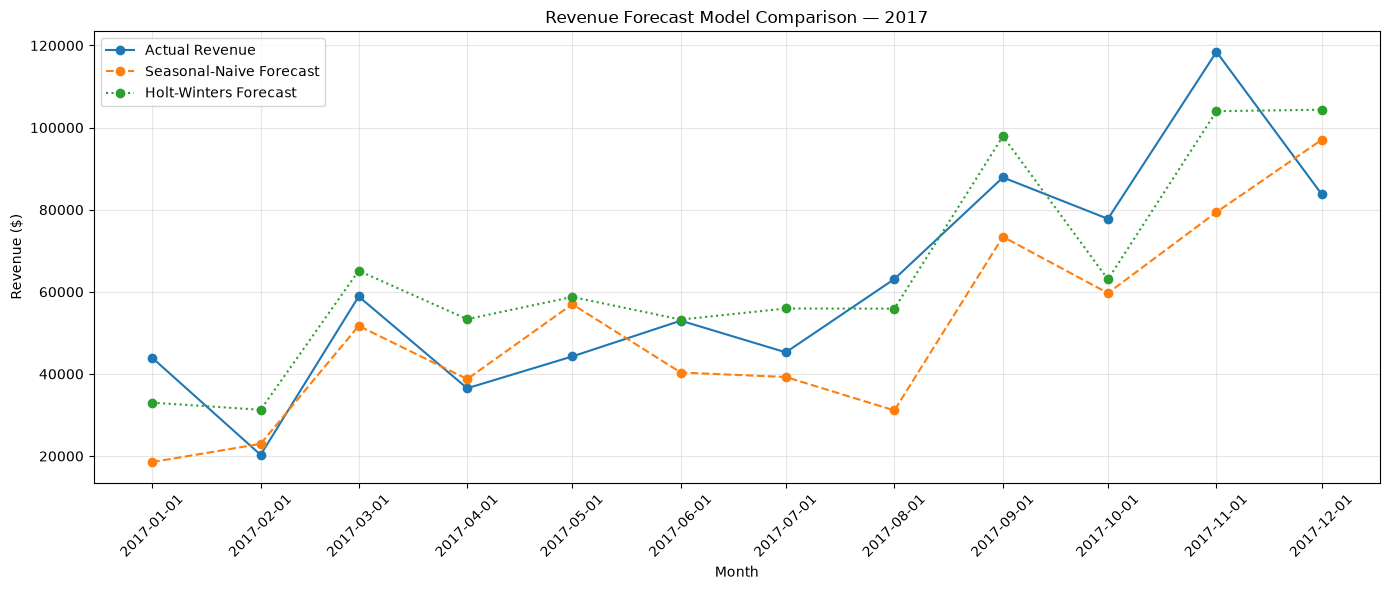

In [75]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    forecast["month_start"],
    forecast["actual_revenue"],
    marker="o",
    label="Actual Revenue"
)

plt.plot(
    forecast["month_start"],
    forecast["forecast_revenue"],
    marker="o",
    linestyle="--",
    label="Seasonal-Naive Forecast"
)

plt.plot(
    hw_results["month_start"],
    hw_results["hw_forecast"],
    marker="o",
    linestyle=":",
    label="Holt-Winters Forecast"
)

plt.title("Revenue Forecast Model Comparison — 2017")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(forecast["month_start"], rotation=45)
plt.tight_layout()
plt.show()


Forecasting Profits

In [76]:

# Train on monthly profit from 2014–2016
train_profit = (
    train.set_index("month_start")["profit"]
    .asfreq("MS")
)

# Fit Holt-Winters with trend and annual seasonality
profit_model = ExponentialSmoothing(
    train_profit,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

profit_fit = profit_model.fit()

# Forecast profit for 2017
profit_predictions = profit_fit.forecast(12)

# Compare predictions with actual profit
profit_results = test[["month_start", "profit"]].copy()
profit_results = profit_results.rename(
    columns={"profit": "actual_profit"}
)

profit_results["forecast_profit"] = profit_predictions.to_numpy()

# Evaluate forecast accuracy
actual_profit = profit_results["actual_profit"]
predicted_profit = profit_results["forecast_profit"]

profit_mae = mean_absolute_error(
    actual_profit, predicted_profit
)

profit_rmse = np.sqrt(
    mean_squared_error(actual_profit, predicted_profit)
)

# MAPE is unstable when actual values are near zero.
# Use it only if actual monthly profit is safely away from zero.
profit_mape = np.mean(
    np.abs((actual_profit - predicted_profit) / actual_profit)
) * 100

print(f"Profit MAE:  ${profit_mae:,.2f}")
print(f"Profit RMSE: ${profit_rmse:,.2f}")
print(f"Profit MAPE: {profit_mape:.2f}%")

display(profit_results.round(2))


Profit MAE:  $3,181.11
Profit RMSE: $3,841.50
Profit MAPE: 101.59%


C:\Users\Aniket Mane\AppData\Local\Temp\ipykernel_29632\4089967939.py:51: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(profit_results.round(2))


,month_start,actual_profit,forecast_profit
36,2017-01-01,7140.44,3581.77
37,2017-02-01,1613.87,6204.68
38,2017-03-01,14751.89,8188.75
39,2017-04-01,933.29,6811.52
40,2017-05-01,6342.58,8885.23
41,2017-06-01,8223.34,7674.44
42,2017-07-01,6952.62,5758.02
43,2017-08-01,9040.96,8139.03
44,2017-09-01,10991.56,12323.70
45,2017-10-01,9275.28,10592.53


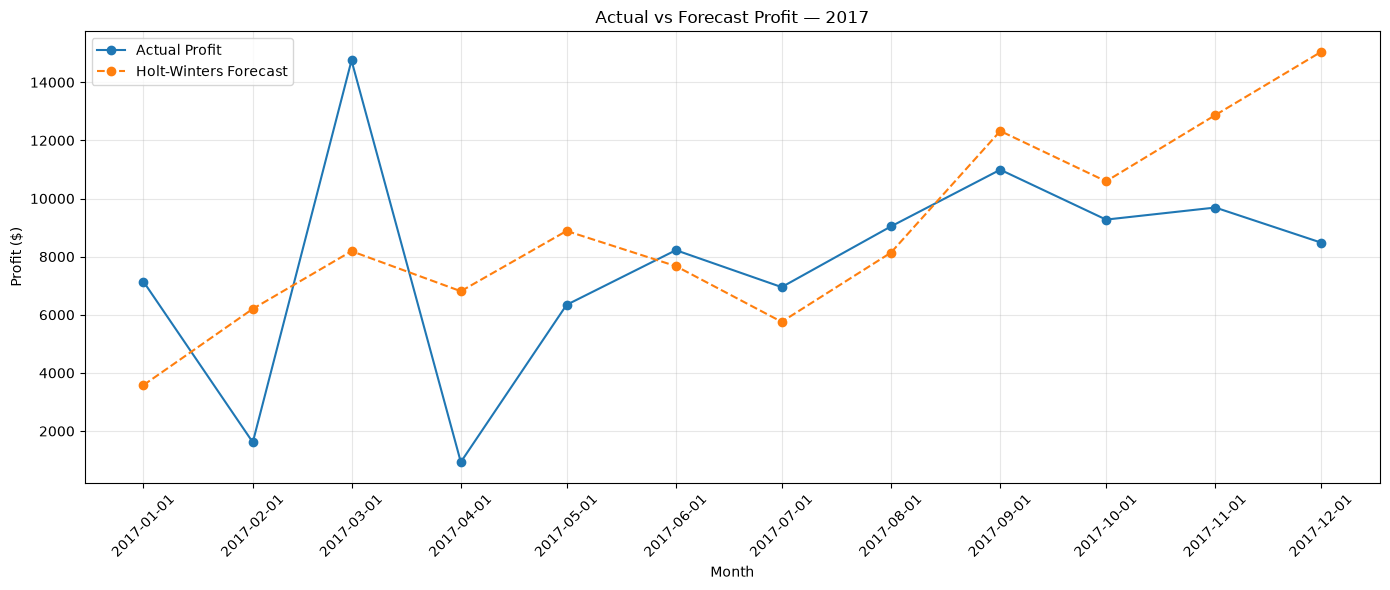

In [77]:

plt.figure(figsize=(14, 6))

plt.plot(
    profit_results["month_start"],
    profit_results["actual_profit"],
    marker="o",
    label="Actual Profit"
)

plt.plot(
    profit_results["month_start"],
    profit_results["forecast_profit"],
    marker="o",
    linestyle="--",
    label="Holt-Winters Forecast"
)

plt.title("Actual vs Forecast Profit — 2017")
plt.xlabel("Month")
plt.ylabel("Profit ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(profit_results["month_start"], rotation=45)
plt.tight_layout()
plt.show()


## Forecasting — Executive Summary

### Revenue Forecasting
Two models were evaluated using 2014–2016 data to predict monthly revenue in 2017.

- **Seasonal-naive:** MAE $15,467.89; RMSE $18,985.70; MAPE 24.52%.
- **Holt-Winters:** MAE $11,452.92; RMSE $12,540.90; MAPE 22.59%.

Holt-Winters performed better on all three metrics in this test period. However, it still missed several monthly fluctuations, including the November revenue peak.

### Profit Forecasting
The Holt-Winters profit forecast achieved MAE of $3,181.11 and RMSE of $3,841.50. Its MAPE was 101.59%, which should be interpreted cautiously because percentage errors can become large when actual monthly profit is small.

### Business Implications
Revenue shows a general upward trend and stronger late-year performance. Forecasts can support preliminary sales planning, but uncertainty remains. Profit forecasts require further evaluation against a baseline and should not be treated as reliable financial commitments.

### Limitations
- Only 48 monthly observations are available.
- The test set covers one year.
- Monthly revenue spikes and profit fluctuations are not fully captured.
- Forecast performance should be validated on additional periods or through rolling time-series validation before operational use.

In [78]:

# Seasonal-naive profit forecast using the same month from 2016
previous_year_profit = (
    train.set_index("month_start")["profit"]
)

profit_results["naive_forecast"] = [
    previous_year_profit.loc[
        date - pd.DateOffset(years=1)
    ]
    for date in profit_results["month_start"]
]

# Evaluate both profit forecasts
actual_profit = profit_results["actual_profit"]

naive_profit = profit_results["naive_forecast"]
hw_profit = profit_results["forecast_profit"]

for model_name, predictions in [
    ("Seasonal Naive", naive_profit),
    ("Holt-Winters", hw_profit)
]:
    mae = mean_absolute_error(actual_profit, predictions)
    rmse = np.sqrt(mean_squared_error(actual_profit, predictions))

    print(f"\n{model_name}")
    print(f"MAE:  ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")



Seasonal Naive
MAE:  $4,991.11
RMSE: $5,794.08

Holt-Winters
MAE:  $3,181.11
RMSE: $3,841.50
